# Власне донавчання: виявлення спаму в SMS

Тема проекту: класифікація SMS на спам і звичайні повідомлення (ham). Донавчаємо модель BERT з новою головою.

## 1.1. Задача

Треба визначати, чи є SMS спамом. На вхід іде текст повідомлення англійською, на виході клас `ham` (звичайне) або `spam` (реклама, розіграші, платні підписки).

Таким фільтром може користуватись оператор зв'язку або застосунок для повідомлень: спам іде в окрему папку, решта приходить як звичайно.

Промпту тут замало. Повідомлень дуже багато, і гнати кожне через велику LLM дорого та довго. Крім того, що вважати спамом, залежить від розмітки в даних, а не від інструкції: ознаки типу коротких номерів чи фраз «txt WIN to…» важко описати словами. Невелика донавчена модель працює швидко, може стояти локально й видає ймовірність спаму, тому поріг можна підібрати. RAG не потрібен, бо ми не шукаємо факти.

## 1.2. Модель і дані

Модель: bert-base-cased. Для класифікації короткого тексту вистачає енкодера, генеративна LLM тут не потрібна. Беремо base, бо instruct-версій у BERT немає, а голову ми й так навчаємо з нуля. Розмір base (110 млн параметрів) без проблем влазить у T4. Вибрали cased, бо в спамі багато слів великими літерами (FREE, WIN), тож регістр може допомагати.

Дані: SMS Spam Collection (Almeida, Hidalgo), на Hugging Face це `ucirvine/sms_spam`. Ліцензія CC BY 4.0 (так вказано на UCI, на сторінці Hugging Face ліцензії немає). 5574 повідомлення англійською, колонки `sms` (текст) і `label` (0 це ham, 1 це spam).

Поділ: спочатку прибираємо дублікати, щоб однакові тексти не були і в train, і в test. Потім ділимо 70 / 15 / 15 так, щоб частка спаму в кожній частині була однаковою (seed 42).

In [13]:
# 1.2 Код: бібліотеки і пристрій
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset, DatasetDict
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.model_selection import train_test_split
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Пристрій:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name())

Пристрій: cuda
GPU: Tesla T4


In [14]:
# 1.2 Код: завантаження даних і приклади
raw = load_dataset("ucirvine/sms_spam", split="train")
df = raw.to_pandas()
df["sms"] = df["sms"].str.strip()
print("Усього повідомлень:", len(df))
print("Дублікатів тексту:", df["sms"].duplicated().sum())

df = df.drop_duplicates("sms").reset_index(drop=True)
print("Після видалення дублікатів:", len(df))
print(df["label"].map({0: "ham", 1: "spam"}).value_counts())

for lab in (0, 1):
    print("\nПриклади", "ham" if lab == 0 else "spam")
    for t in df[df["label"] == lab]["sms"].sample(3, random_state=1):
        print("-", t)

Усього повідомлень: 5574
Дублікатів тексту: 414
Після видалення дублікатів: 5160
label
ham     4518
spam     642
Name: count, dtype: int64

Приклади ham
- Am also doing in cbe only. But have to pay.
- Babe ! How goes that day ? What are you doing ? Where are you ? I sip my cappuccino and think of you, my love ... I send a kiss to you from across the sea
- TELL HER I SAID EAT SHIT.

Приклади spam
- FREE entry into our £250 weekly comp just send the word ENTER to 84128 NOW. 18 T&C www.textcomp.com cust care 08712405020.
- 3. You have received your mobile content. Enjoy
- If you don't, your prize will go to another customer. T&C at www.t-c.biz 18+ 150p/min Polo Ltd Suite 373 London W1J 6HL Please call back if busy


In [15]:
# 1.2 Код: поділ на train / validation / test
train_df, rest_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=rest_df["label"], random_state=42)

# перевірка: тестові тексти не потрапили в тренування
assert not set(test_df["sms"]) & set(train_df["sms"])
assert not set(val_df["sms"]) & set(train_df["sms"])
assert not set(test_df["sms"]) & set(val_df["sms"])

pd.DataFrame({
    "набір": ["train", "validation", "test"],
    "повідомлень": [len(train_df), len(val_df), len(test_df)],
    "spam": [int(d["label"].sum()) for d in (train_df, val_df, test_df)],
    "spam, %": [round(100 * d["label"].mean(), 1) for d in (train_df, val_df, test_df)],
})

,набір,повідомлень,spam,"spam, %"
0,train,3612,449,12.4
1,validation,774,97,12.5
2,test,774,96,12.4


In [16]:
# 1.2 Код: токенізація
checkpoint = "bert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)


def to_ds(d):
    return Dataset.from_pandas(d[["sms", "label"]].reset_index(drop=True))


ds = DatasetDict(train=to_ds(train_df), validation=to_ds(val_df), test=to_ds(test_df))
tok = ds.map(lambda b: tokenizer(b["sms"], truncation=True, max_length=128), batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

lens = [len(x) for x in tok["train"]["input_ids"]]
print("Довжина в токенах: середня", round(np.mean(lens), 1), ", максимальна", max(lens))
print("Обрізано до 128 токенів:", sum(l == 128 for l in lens), "повідомлень")

Map:   0%|          | 0/3612 [00:00<?, ? examples/s]

Map:   0%|          | 0/774 [00:00<?, ? examples/s]

Map:   0%|          | 0/774 [00:00<?, ? examples/s]

Довжина в токенах: середня 26.7 , максимальна 128
Обрізано до 128 токенів: 8 повідомлень


## 1.3. Модель до донавчання

Метрика: головна це F1 для класу spam, ще дивимось на accuracy, precision і recall. Спаму помітно менше, ніж звичайних повідомлень, тому за однією accuracy модель, яка завжди каже ham, виглядала б непогано, хоча жодного спаму не знаходить (її F1 дорівнює 0). F1 враховує і пропущений спам, і хибні спрацювання.

Базовий рівень: відповідь «завжди найчастіший клас». Ще оцінюємо BERT з новою головою, яку поки не навчали, там відповіді мають бути майже навмання.

In [17]:
# 1.3 Код: метрики і базовий рівень
def calc_metrics(labels, preds):
    p, r, f, _ = precision_recall_fscore_support(labels, preds, average='binary', pos_label=1, zero_division=0)
    return {'accuracy': accuracy_score(labels, preds), 'precision': p, 'recall': r, 'f1': f}


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return calc_metrics(labels, np.argmax(logits, axis=-1))


y_test = np.array(ds['test']['label'])
majority = int(train_df['label'].mode()[0])
baseline = calc_metrics(y_test, np.full_like(y_test, majority))
print('Найчастіший клас у train:', 'spam' if majority else 'ham')
baseline

Найчастіший клас у train: ham


{'accuracy': 0.875968992248062, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}

In [18]:
# 1.3 Код: BERT з новою (ще не навченою) головою на тестовому наборі
set_seed(42)
model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint, num_labels=2, id2label={0: 'ham', 1: 'spam'}, label2id={'ham': 0, 'spam': 1}
)

eval_args = TrainingArguments(output_dir='tmp_eval', per_device_eval_batch_size=64, fp16=torch.cuda.is_available(), report_to='none')
trainer0 = Trainer(model=model, args=eval_args, eval_dataset=tok['test'], data_collator=data_collator, compute_metrics=compute_metrics)
res = trainer0.evaluate()
before = {k: res['eval_' + k] for k in ('accuracy', 'precision', 'recall', 'f1')}
before

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
No log,0.768704,0,0.124031,0.124031,1.000000,0.220690


{'accuracy': 0.12403100775193798,
 'precision': 0.12403100775193798,
 'recall': 1.0,
 'f1': 0.2206896551724138}

In [19]:
# 1.3 Код: приклади відповідей моделі до донавчання
def spam_proba(model, texts):
    model.eval()
    enc = tokenizer(list(texts), truncation=True, max_length=128, padding=True, return_tensors='pt').to(model.device)
    with torch.no_grad():
        return model(**enc).logits.softmax(-1)[:, 1].cpu().numpy()


rng = np.random.RandomState(7)
spam_idx = rng.choice(np.where(y_test == 1)[0], 4, replace=False)
ham_idx = rng.choice(np.where(y_test == 0)[0], 4, replace=False)
ex_idx = np.concatenate([spam_idx, ham_idx])
ex_texts = [ds['test'][int(i)]['sms'] for i in ex_idx]
ex_true = y_test[ex_idx]

ex_before = spam_proba(model, ex_texts)
examples = pd.DataFrame({
    'SMS': [t[:70] + ('...' if len(t) > 70 else '') for t in ex_texts],
    'справжній клас': ['spam' if y else 'ham' for y in ex_true],
    'P(spam) до донавчання': ex_before.round(3),
})
pd.set_option('display.max_colwidth', 80)
examples

,SMS,справжній клас,P(spam) до донавчання
0,No 1 POLYPHONIC tone 4 ur mob every week! Just txt PT2 to 87575. 1st T...,spam,0.546
1,Here is your discount code RP176781. To stop further messages reply st...,spam,0.554
2,Your weekly Cool-Mob tones are ready to download !This weeks new Tones...,spam,0.581
3,You are a winner U have been specially selected 2 receive £1000 cash o...,spam,0.564
4,Hanging out with my brother and his family,ham,0.538
5,Cos i was out shopping wif darren jus now n i called him 2 ask wat pre...,ham,0.546
6,Eh u remember how 2 spell his name... Yes i did. He v naughty make unt...,ham,0.555
7,I just made some payments so dont have that much. Sorry. Would you wan...,ham,0.551


## 1.4. Донавчання

Метод: повне донавчання з новою головою, як у демо 01, тобто оновлюються всі ваги BERT і голова. Для нашого датасету цього вистачає, тому LoRA не беремо.

Гіперпараметри: learning rate 2e-5 (малий, щоб не зіпсувати те, що модель уже знає), 3 епохи, батч 32, weight decay 0.01, 30 кроків розігріву, змішана точність fp16. Після кожної епохи рахуємо loss і метрики на validation. Тестовий набір у навчанні не використовуємо.

In [20]:
# 1.4 Код: донавчання
args = TrainingArguments(
    output_dir='bert-sms-spam',
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    warmup_steps=30,
    eval_strategy='epoch',
    save_strategy='no',
    logging_steps=20,
    fp16=torch.cuda.is_available(),
    report_to='none',
    seed=42,
)
trainer = Trainer(model=model, args=args, train_dataset=tok['train'], eval_dataset=tok['validation'], data_collator=data_collator, compute_metrics=compute_metrics)

torch.cuda.reset_peak_memory_stats()
start = time.time()
trainer.train()
train_minutes = (time.time() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1024**3
print(f'Тривалість тренування: {train_minutes:.2f} хв')
print(f'Пікова памʼять GPU: {peak_gb:.2f} GB')

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.080241,0.053360,0.985788,0.947917,0.938144,0.943005
2,0.029300,0.045632,0.989664,0.989011,0.927835,0.957447
3,0.001169,0.061066,0.987080,0.948454,0.948454,0.948454


Тривалість тренування: 0.82 хв
Пікова памʼять GPU: 3.02 GB


,training loss,validation loss,accuracy,precision,recall,f1
епоха,,,,,,
1,0.2218,0.0534,0.9858,0.9479,0.9381,0.9430
2,0.0248,0.0456,0.9897,0.9890,0.9278,0.9574
3,0.0082,0.0611,0.9871,0.9485,0.9485,0.9485


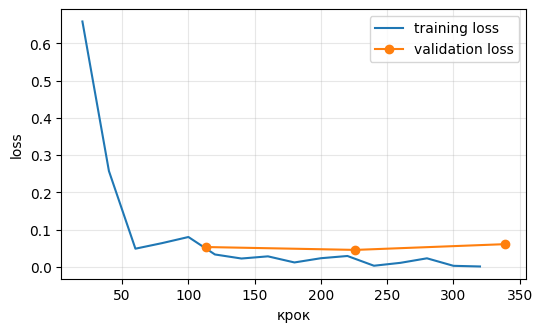

In [21]:
# 1.4 Код: training і validation loss по епохах
log = pd.DataFrame(trainer.state.log_history)
tr = log.dropna(subset=['loss']).copy()
tr['epoch_n'] = np.ceil(tr['epoch']).astype(int)
ev = log.dropna(subset=['eval_loss']).copy()
ev['epoch_n'] = ev['epoch'].round().astype(int)
ev_i = ev.set_index('epoch_n')

loss_table = pd.DataFrame({
    'training loss': tr.groupby('epoch_n')['loss'].mean(),
    'validation loss': ev_i['eval_loss'],
    'accuracy': ev_i['eval_accuracy'],
    'precision': ev_i['eval_precision'],
    'recall': ev_i['eval_recall'],
    'f1': ev_i['eval_f1'],
}).round(4)
loss_table.index.name = 'епоха'
display(loss_table)

plt.figure(figsize=(6, 3.5))
plt.plot(tr['step'], tr['loss'], label='training loss')
plt.plot(ev['step'], ev['eval_loss'], 'o-', label='validation loss')
plt.xlabel('крок')
plt.ylabel('loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

1.4 Текст: Бачимо перенавчання: на третій епосі validation loss виріс (з 0.0456 до 0.0611), хоча training loss далі падав (з 0.0248 до 0.0082), а F1 на validation знизився з 0.9574 до 0.9485. Тому тренуємо модель ще раз, але тепер лише 2 епохи, решту параметрів не змінюємо. Далі в 1.5 використовуємо вже цю модель.

In [22]:
# 1.4 Код: повторне донавчання, 2 епохи
import gc

# звільняємо памʼять від першої моделі, щоб пікова памʼять рахувалась чесно
del trainer, trainer0, model
gc.collect()
torch.cuda.empty_cache()

set_seed(42)
model2 = AutoModelForSequenceClassification.from_pretrained(
    checkpoint, num_labels=2, id2label={0: 'ham', 1: 'spam'}, label2id={'ham': 0, 'spam': 1}
)
args2 = TrainingArguments(
    output_dir='bert-sms-spam-2ep',
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    warmup_steps=30,
    eval_strategy='epoch',
    save_strategy='no',
    logging_steps=20,
    fp16=torch.cuda.is_available(),
    report_to='none',
    seed=42,
)
trainer2 = Trainer(model=model2, args=args2, train_dataset=tok['train'], eval_dataset=tok['validation'], data_collator=data_collator, compute_metrics=compute_metrics)

torch.cuda.reset_peak_memory_stats()
start = time.time()
trainer2.train()
train_minutes2 = (time.time() - start) / 60
peak_gb2 = torch.cuda.max_memory_allocated() / 1024**3
print(f'Тривалість тренування: {train_minutes2:.2f} хв')
print(f'Пікова памʼять GPU: {peak_gb2:.2f} GB')

# у розділі 1.5 працюємо саме з цією моделлю
trainer = trainer2

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.073918,0.048823,0.989664,0.978495,0.938144,0.957895
2,0.024268,0.054998,0.985788,0.938776,0.948454,0.943590


Тривалість тренування: 0.54 хв
Пікова памʼять GPU: 3.01 GB


In [23]:
# 1.4 Код: training і validation loss, 2 епохи
log2 = pd.DataFrame(trainer2.state.log_history)
tr2 = log2.dropna(subset=['loss']).copy()
tr2['epoch_n'] = np.ceil(tr2['epoch']).astype(int)
ev2 = log2.dropna(subset=['eval_loss']).copy()
ev2['epoch_n'] = ev2['epoch'].round().astype(int)
ev2 = ev2.set_index('epoch_n')

loss_table2 = pd.DataFrame({
    'training loss': tr2.groupby('epoch_n')['loss'].mean(),
    'validation loss': ev2['eval_loss'],
    'accuracy': ev2['eval_accuracy'],
    'precision': ev2['eval_precision'],
    'recall': ev2['eval_recall'],
    'f1': ev2['eval_f1'],
}).round(4)
loss_table2.index.name = 'епоха'
loss_table2

,training loss,validation loss,accuracy,precision,recall,f1
епоха,,,,,,
1,0.2201,0.0488,0.9897,0.9785,0.9381,0.9579
2,0.0228,0.0550,0.9858,0.9388,0.9485,0.9436


## 1.5. Порівняння

Порівнюємо модель до і після донавчання на тому самому тестовому наборі та на тих самих 8 прикладах з пункту 1.3, а потім розбираємо помилки.

In [24]:
# 1.5 Код: метрики до і після донавчання на тесті
pred_out = trainer.predict(tok['test'])
logits = pred_out.predictions
test_pred = logits.argmax(-1)
test_proba = torch.tensor(logits).softmax(-1)[:, 1].numpy()
after = calc_metrics(y_test, test_pred)

comparison = pd.DataFrame(
    {'завжди ham': baseline, 'BERT до донавчання': before, 'BERT після донавчання': after}
).T.round(4)
display(comparison)

cm = confusion_matrix(y_test, test_pred)
print('Матриця помилок після донавчання (рядки: справжній клас, стовпці: передбачений)')
display(pd.DataFrame(cm, index=['ham', 'spam'], columns=['передбачено ham', 'передбачено spam']))

,accuracy,precision,recall,f1
завжди ham,0.8760,0.0000,0.0,0.0000
BERT до донавчання,0.1240,0.1240,1.0,0.2207
BERT після донавчання,0.9987,0.9897,1.0,0.9948


Матриця помилок після донавчання (рядки: справжній клас, стовпці: передбачений)


,передбачено ham,передбачено spam
ham,677,1
spam,0,96


In [25]:
# 1.5 Код: ті самі приклади до і після
ex_after = spam_proba(trainer.model, ex_texts)
examples['P(spam) після донавчання'] = ex_after.round(3)
examples['передбачено після'] = np.where(ex_after > 0.5, 'spam', 'ham')
examples

,SMS,справжній клас,P(spam) до донавчання,P(spam) після донавчання,передбачено після
0,No 1 POLYPHONIC tone 4 ur mob every week! Just txt PT2 to 87575. 1st T...,spam,0.546,0.999,spam
1,Here is your discount code RP176781. To stop further messages reply st...,spam,0.554,0.999,spam
2,Your weekly Cool-Mob tones are ready to download !This weeks new Tones...,spam,0.581,0.996,spam
3,You are a winner U have been specially selected 2 receive £1000 cash o...,spam,0.564,0.999,spam
4,Hanging out with my brother and his family,ham,0.538,0.003,ham
5,Cos i was out shopping wif darren jus now n i called him 2 ask wat pre...,ham,0.546,0.001,ham
6,Eh u remember how 2 spell his name... Yes i did. He v naughty make unt...,ham,0.555,0.001,ham
7,I just made some payments so dont have that much. Sorry. Would you wan...,ham,0.551,0.001,ham


In [26]:
# 1.5 Код: помилки донавченої моделі
test_view = test_df.reset_index(drop=True).copy()
test_view['p_spam'] = test_proba.round(3)
test_view['pred'] = test_pred
errors = test_view[test_view['label'] != test_view['pred']]
print('Помилок:', len(errors), 'з', len(test_view))

for kind, name in ((0, 'звичайні SMS, позначені як spam (FP)'), (1, 'спам, який пропущено (FN)')):
    part = errors[errors['label'] == kind]
    print()
    print(name + ':', len(part))
    for _, row in part.iterrows():
        print('- [' + str(row['p_spam']) + ']', row['sms'])

Помилок: 1 з 774

звичайні SMS, позначені як spam (FP): 1
- [0.9959999918937683] Total video converter free download type this in google search:)

спам, який пропущено (FN): 0


In [27]:
# 1.5 Код: найменш певні відповіді моделі (найближчі до 0.5)
test_view['відстань до 0.5'] = (test_view['p_spam'] - 0.5).abs()
close = test_view.sort_values('відстань до 0.5').head(6)
for _, row in close.iterrows():
    print('[' + str(row['p_spam']) + ']', 'справжній:', 'spam' if row['label'] else 'ham', '|', row['sms'])

[0.22499999403953552] справжній: ham | Double eviction this week - Spiral and Michael and good riddance to them!
[0.890999972820282] справжній: spam | Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinions. I want to be your friend 1/1
[0.8989999890327454] справжній: spam | Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!
[0.09099999815225601] справжній: ham | I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to  &lt;#&gt;
[0.9649999737739563] справжній: spam | TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the next link sent to ur fone...
[0.027000000700354576] справжній: ham | Forgot you were working today! Wanna chat, but things are ok so drop me a text when you're free / bored etc and 

## 1.6. Мій звіт

**Задача і чому потрібне донавчання:** фільтр спаму для SMS. На вході текст повідомлення, на виході ham або spam. Через велику LLM з промптом таке робити дорого й повільно, коли повідомлень багато, а межу між спамом і звичайними SMS краще вивчити з розмічених прикладів. Тому донавчили невелику модель.

**Модель і дані:** bert-base-cased (110 млн параметрів) з новою головою на 2 класи. Дані: SMS Spam Collection (`ucirvine/sms_spam` на Hugging Face), ліцензія CC BY 4.0. З 5574 повідомлень після видалення 414 дублікатів лишилось 5160 (4518 ham і 642 spam). Поділили 70 / 15 / 15 зі збереженням частки спаму (близько 12.4%): train 3612, validation 774, test 774. Тестові тексти в train не потрапляли.

**Метрика й результат до донавчання:** головна метрика F1 для класу spam, бо спаму лише близько 12%. Базовий рівень «завжди ham» дає accuracy 0.8760, але F1 дорівнює 0. BERT із ще не навченою головою всім повідомленням ставить spam (P(spam) від 0.54 до 0.58): accuracy 0.1240, F1 0.2207.

**Метод донавчання й гіперпараметри:** повне донавчання (всі ваги BERT і нова голова) через Trainer. Learning rate 2e-5, батч 32, weight decay 0.01, 30 кроків розігріву, fp16, 2 епохи. Спочатку було 3 епохи, але на третій validation loss виріс (0.0456 → 0.0611) при тому, що training loss далі падав, тому скоротили до 2. Різниця невелика: validation loss на останній епосі 0.0550 проти 0.0611, а F1 на validation 0.9436 проти 0.9485, тобто в межах шуму, бо у validation лише 97 спам-повідомлень. Тренування на T4 тривало 0.54 хв, пікова памʼять GPU 3.01 GB.

**Результат після донавчання:** на тесті accuracy 0.9987, precision 0.9897, recall 1.0, F1 0.9948. Усі 96 спам-повідомлень знайдено, а зі 678 звичайних одне помилково позначене як spam. Усі 8 прикладів з пункту 1.3 тепер класифіковані правильно: для спаму P(spam) 0.996–0.999, для звичайних SMS 0.001–0.003.

**Аналіз помилок:** помилка одна: «Total video converter free download type this in google search:)» (ham, P(spam) 0.996). Повідомлення схоже на спам: є слова free і download та заклик щось зробити, тому модель відреагувала на них, хоча це лист між знайомими. Серед найменш упевнених відповідей ham «Double eviction this week…» (0.225) схоже на розсилки через «this week», а spam «Guess who am I?…» (0.899) і «Xmas & New Years Eve tickets…» (0.891) не містять типових ознак розіграшу й схожі на звичайний текст. Ще є ham «I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS» (0.091), яке за змістом скоріше реклама, тож розмітка датасету не ідеальна. Обмеження: у тесті лише 96 спам-повідомлень і 1 помилка, тому F1 0.9948 дуже приблизний, а дані старі й англійською.

**Висновок:** донавчений BERT добре виявляє спам: F1 0.9948 проти 0.2207 до донавчання, а «завжди ham» не знаходить жодного спаму. Тренування вкладається в хвилину на T4. Щоб використовувати це на практиці, модель ще треба перевірити на свіжих SMS і українською та підібрати поріг під ціну помилок.